# 06 — Initial Feature Importance Analysis
**Day 6 · Phase 3**

### Objectives
Train a preliminary Random Forest and ask: *which features does a fitted model actually rely on?* Compare its
answer with the Day 5 statistical rankings.

### Three kinds of importance
| Method | How it's computed | Strengths | Limitations |
|---|---|---|---|
| **Impurity (MDI)** | Sum of the variance (MSE) reduction from every split on a feature, averaged over trees | Free, fast | Computed on *training* data, so it rewards features the model used to memorise; biased toward features with many distinct values; shared between correlated features |
| **Permutation** | Shuffle one feature in *held-out* data and measure how much the error grows | Measures real predictive value on unseen data; model-agnostic | Correlated features cover for each other (shuffling one barely hurts), so both look less important |
| **Shapley values (SHAP)** | Fair split of each individual prediction among features (game theory) | Local + global; signed direction | Expensive; still reflects the model, not causality |

**Importance ≠ correlation ≠ causation.** Correlation measures a one-feature association; importance measures how much
*this model* uses a feature given all the others. Neither says that changing the feature changes the price.

Validation design: the Random Forest is trained on 4/5 of the training models and permutation importance is measured
on the remaining 1/5 (a grouped split **inside the training set**). The real test set stays untouched until Day 9.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

from src.train import load_model_ready_data, xy
from src.feature_engineering import make_preprocessor, ENGINEERED_COLUMNS, SpecFeatureBuilder
from src.evaluate import regression_metrics
from src.preprocessing import MODEL_INPUT_COLUMNS

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
fit_idx, val_idx = next(gss.split(X_tr, y_tr, groups=g_tr))
X_fit, X_val = X_tr.iloc[fit_idx], X_tr.iloc[val_idx]
y_fit, y_val = y_tr.iloc[fit_idx], y_tr.iloc[val_idx]
print(f"Fit: {len(X_fit)} rows | validation: {len(X_val)} rows from {g_tr.iloc[val_idx].nunique()} unseen models")

rf = Pipeline([("prep", make_preprocessor()),
               ("model", RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))])
rf_log = TransformedTargetRegressor(regressor=rf, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
rf_log.fit(X_fit, y_fit)
pd.DataFrame({"fit": regression_metrics(y_fit, rf_log.predict(X_fit)),
              "validation (unseen models)": regression_metrics(y_val, rf_log.predict(X_val))}).T

Fit: 324 rows | validation: 95 rows from 28 unseen models


,MAE,RMSE,R2,MAPE_%
fit,797.010,"1,771.810",0.974,4.139
validation (unseen models),"3,376.670","6,693.813",0.542,14.157


**Interpretation.** The gap is large: fit R² 0.97 (MAE ₹797) vs validation R² 0.54 (MAE ₹3,377) on 28 unseen models.
The forest nearly memorises the phones it saw. That's expected for a preliminary, untuned forest and
is exactly why impurity importance (computed on training data) needs a held-out cross-check.

## 1. Impurity-based importance (MDI)

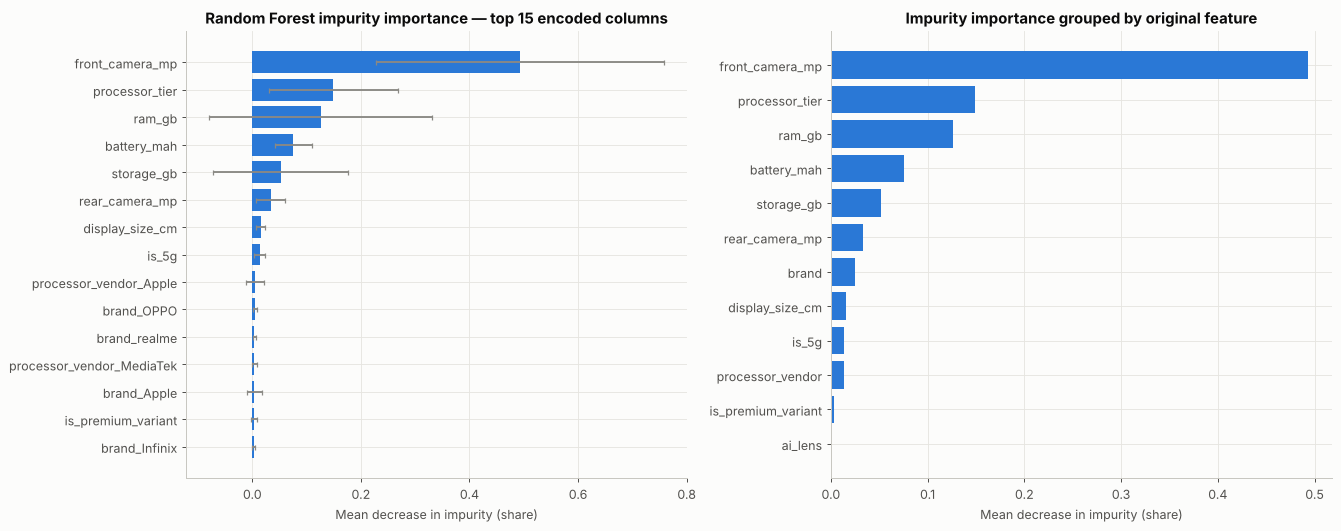

,front_camera_mp,processor_tier,ram_gb,battery_mah,storage_gb,rear_camera_mp,brand,display_size_cm,is_5g,processor_vendor,is_premium_variant,ai_lens
MDI,0.493,0.149,0.126,0.075,0.052,0.034,0.025,0.015,0.014,0.013,0.004,0.001


In [2]:
forest = rf_log.regressor_.named_steps["model"]
enc_names = rf_log.regressor_.named_steps["prep"].get_feature_names_out() if hasattr(rf_log.regressor_.named_steps["prep"], "get_feature_names_out") else None
enc_names = rf_log.regressor_.named_steps["prep"].named_steps["encode"].get_feature_names_out()
mdi = pd.Series(forest.feature_importances_, index=enc_names)
tree_std = pd.Series(np.std([t.feature_importances_ for t in forest.estimators_], axis=0), index=enc_names)

def group_name(col):
    for base in ["processor_vendor", "brand"]:
        if col.startswith(base + "_"):
            return base
    return col
mdi_grouped = mdi.groupby(group_name).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = mdi.sort_values(ascending=False).head(15).iloc[::-1]
axes[0].barh(top.index, top.values, xerr=tree_std[top.index], color=PRIMARY, ecolor="#8a8984", capsize=2)
axes[0].set(title="Random Forest impurity importance — top 15 encoded columns", xlabel="Mean decrease in impurity (share)")
g = mdi_grouped.iloc[::-1]
axes[1].barh(g.index, g.values, color=PRIMARY)
axes[1].set(title="Impurity importance grouped by original feature", xlabel="Mean decrease in impurity (share)")
fig.tight_layout(); save_fig(fig, "fi_rf_impurity")
mdi_grouped.round(3).to_frame("MDI").T

**How to read this.** Each bar is the share of the total variance reduction (in log price) achieved by splits on
that feature; bars sum to 1. Error bars show the spread across trees. Grouping one-hot columns back to their source
variable (right panel) gives a fairer view of brand and vendor.

**Interpretation.** **Front camera takes almost half of all impurity reduction (0.49)**, far ahead of processor tier
(0.15) and RAM (0.13). Its discrete values (5/8 MP budget, 13/16 MP mid, 32–60 MP premium) separate price bands
cleanly, so the trees pick it for the top splits, and the top splits get credited with the largest variance
reductions. Because storage, RAM, tier and front camera are correlated, whichever one wins the early splits collects
the credit the others would otherwise share. That's a known MDI bias, so we cross-check with permutation importance.

## 2. Permutation importance on held-out models

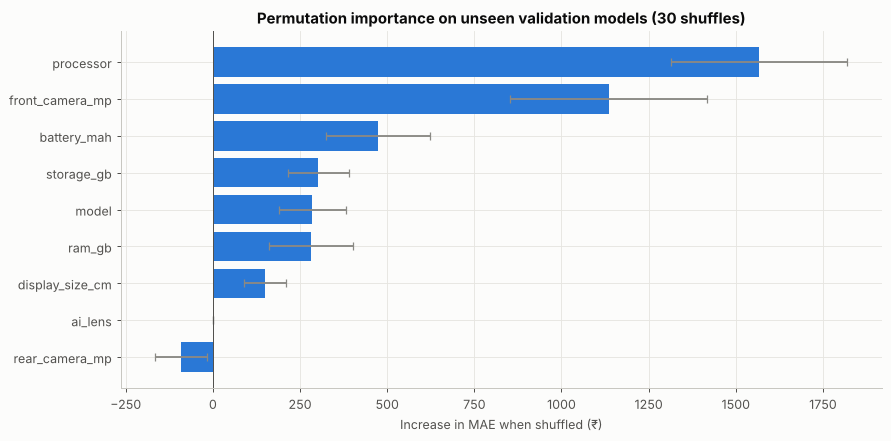

,increase_in_MAE,std
processor,"1,567.100",253.100
front_camera_mp,"1,135.200",282.100
battery_mah,472.300,149.200
storage_gb,302.100,87.900
model,285.600,95.200
ram_gb,281.800,120.600
display_size_cm,150.300,60.600
ai_lens,0.000,0.000
rear_camera_mp,-91.200,74.400


In [3]:
perm = permutation_importance(rf_log, X_val, y_val, scoring="neg_mean_absolute_error",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
# Permuting raw inputs: brand & 5G/premium flags come from `model`, tier & vendor from `processor`.
perm_df = pd.DataFrame({"increase_in_MAE": perm.importances_mean, "std": perm.importances_std},
                       index=X_val.columns).sort_values("increase_in_MAE", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
p = perm_df.iloc[::-1]
ax.barh(p.index, p["increase_in_MAE"], xerr=p["std"], color=PRIMARY, ecolor="#8a8984", capsize=3)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Permutation importance on unseen validation models (30 shuffles)", xlabel="Increase in MAE when shuffled (₹)")
fig.tight_layout(); save_fig(fig, "fi_rf_permutation")
perm_df.round(1)

**How to read this.** Permutation is applied to the **raw model inputs**, so `processor` stands for tier + vendor
together, and `model` for brand + 5G + premium flags together — what a pricing analyst would actually change. A bar of
₹X means validation MAE rises by about ₹X when that input is randomly shuffled. Bars near zero (or negative) mean the
model doesn't need the input on unseen phones, either because it's uninformative or because a correlated input covers
for it.

## 3. Comparing model importance with correlation and mutual information

In [4]:
rel = pd.read_csv(PROJECT_ROOT / "reports" / "feature_relevance.csv", index_col=0)
# Bring everything to the level of original inputs for a like-for-like comparison.
to_input = {"processor_tier": "processor", "processor_vendor": "processor", "brand": "model",
            "is_5g": "model", "is_premium_variant": "model"}
def input_of(col):
    return to_input.get(group_name(col), group_name(col))

cmp = pd.DataFrame({
    "spearman |ρ| (max within input)": rel["|spearman|"].groupby(input_of).max(),
    "mutual info (max within input)": rel["mutual_info"].groupby(input_of).max(),
    "RF impurity (sum)": mdi.groupby(input_of).sum(),
    "RF permutation ΔMAE ₹": perm_df["increase_in_MAE"],
})
ranks = cmp.rank(ascending=False).astype(int)
ranks.columns = [c.split(" (")[0].split(" Δ")[0] + " rank" for c in cmp.columns]
summary = cmp.round(3).join(ranks).sort_values("RF permutation rank")
summary

,spearman |ρ| (max within input),mutual info (max within input),RF impurity (sum),RF permutation ΔMAE ₹,spearman |ρ| rank,mutual info rank,RF impurity rank,RF permutation rank
processor,0.859,0.780,0.162,"1,567.096",1,1,2,1
front_camera_mp,0.789,0.714,0.493,"1,135.232",4,4,1,2
battery_mah,0.458,0.324,0.075,472.341,7,8,4,3
storage_gb,0.814,0.740,0.052,302.058,2,2,5,4
model,0.597,0.326,0.042,285.568,5,7,6,5
ram_gb,0.796,0.723,0.126,281.798,3,3,3,6
display_size_cm,0.222,0.618,0.015,150.313,8,5,8,7
ai_lens,0.191,0.052,0.001,0.000,9,9,9,8
rear_camera_mp,0.573,0.573,0.034,-91.228,6,6,7,9


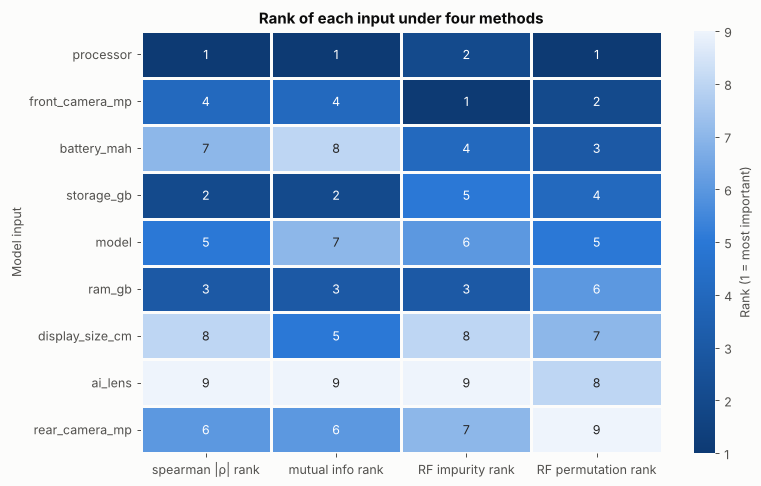

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(ranks.loc[summary.index], annot=True, fmt="d", cmap=SEQUENTIAL.reversed(), ax=ax,
            cbar_kws={"label": "Rank (1 = most important)"}, linewidths=1, linecolor="#fcfcfb")
ax.set(title="Rank of each input under four methods", xlabel="", ylabel="Model input"); ax.grid(False)
fig.tight_layout(); save_fig(fig, "fi_method_rank_comparison")

**Interpretation.**
- **Processor is the most important input on unseen phones** (shuffling it raises MAE by ~₹1,570) and is ranked
  1st or 2nd by every method.
- **Front camera** is 2nd by permutation (+₹1,135) and 1st by impurity. The forest really does use it, not just in
  training.
- **Storage and RAM** rank 2nd–3rd by correlation/MI but only 4th–6th by permutation (~₹300 each). This is the
  **correlation vs predictive importance** distinction: they are strongly associated with price, but once processor
  and front camera are known, the forest gets little *extra* from them, and when one is shuffled the other (they
  correlate at 0.74) covers for it.
- **Battery** ranks higher in permutation (3rd) than in correlation (7th). The forest uses it as a segment marker in
  combination with other specs (e.g. 6,000 mAh + entry chip = budget), an interaction a single correlation can't see.
- **Rear camera** is moderately correlated (ρ 0.57) but its permutation importance is *negative* (−₹91): shuffling it
  slightly improves validation error. The forest has learned rear-camera patterns that don't transfer to new phones
  (12 MP flagships vs 50 MP budget phones), so it's noise for this model.
- **AI lens** contributes nothing.

These are preliminary: the forest is untuned and the validation set has only 28 models, so small rank differences
are noise. Day 10 repeats the analysis with the final model on the real test set.

These are preliminary: the forest is untuned and the validation set has only ~25 models, so small differences in
rank are noise. Day 10 repeats the analysis with the final model on the real test set.

## 4. Shapley-value explanations
The `shap` library isn't required. `src/explain.py` computes **exact interventional Shapley values** over the
9 model inputs: with 9 inputs there are only 2⁹ = 512 feature coalitions, so every coalition is evaluated directly
(no approximation), using 60 training rows as the background distribution. Values are in **log-price units**, so a
contribution of +0.10 means roughly +10.5 % on the predicted price. If `shap` is installed, the cell also runs
`shap.TreeExplainer` on the encoded features as a cross-check.

shap not installed — using exact Shapley values from src/explain.py (equivalent quantity).


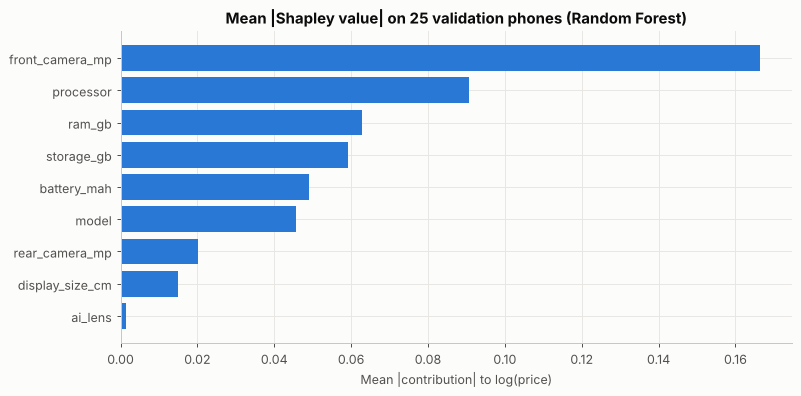

,front_camera_mp,processor,ram_gb,storage_gb,battery_mah,model,rear_camera_mp,display_size_cm,ai_lens
mean |Shapley|,0.166,0.091,0.063,0.059,0.049,0.046,0.020,0.015,0.001


In [6]:
from src.explain import shapley_matrix
background = X_fit.sample(60, random_state=RANDOM_STATE)
explain_rows = X_val.sample(min(25, len(X_val)), random_state=RANDOM_STATE)
sv = shapley_matrix(rf_log, explain_rows, background, log_space=True)

mean_abs = sv.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(mean_abs.index, mean_abs.values, color=PRIMARY)
ax.set(title="Mean |Shapley value| on 25 validation phones (Random Forest)", xlabel="Mean |contribution| to log(price)")
fig.tight_layout(); save_fig(fig, "fi_rf_shapley_global")

try:
    import shap
    enc = rf_log.regressor_.named_steps["prep"]
    expl = shap.TreeExplainer(forest)
    sh = expl.shap_values(enc.transform(explain_rows))
    print("shap package available — TreeExplainer mean |SHAP| (top 8):")
    print(pd.Series(np.abs(sh).mean(0), index=enc_names).sort_values(ascending=False).head(8).round(4).to_dict())
except ImportError:
    print("shap not installed — using exact Shapley values from src/explain.py (equivalent quantity).")
mean_abs.sort_values(ascending=False).round(4).to_frame("mean |Shapley|").T

**Interpretation.** Shapley values rank **front camera first (mean |contribution| 0.166 ≈ ±18 % of price)**, then
processor (0.091), RAM (0.063), storage (0.059), battery (0.049) and the model-name signals (0.046). This forest leans
heavily on front camera. Note the difference between the two measures: Shapley shows how much a feature *moves*
predictions; permutation shows how much *accuracy* is lost without it. Unlike impurity importance
they're measured on unseen phones and are *additive*: for each phone, the contributions add up exactly to the gap
between its prediction and the average prediction. Day 10 uses them to explain individual prices with the final model.

## Preliminary conclusions
1. **Processor (tier/vendor)** and **front camera** are what the forest relies on most for unseen phones.
2. **Storage and RAM** are highly correlated with price but largely redundant with each other and with processor
   once both are present.
3. **Battery** matters more in the model than its correlation suggests (segment-marker interaction).
4. **Rear camera** megapixels and **AI lens** add no predictive value on unseen phones; display size little.
5. Impurity importance concentrates credit on early-split features; permutation and Shapley values are preferred.
6. A single untuned forest's view is model-specific. Day 10 checks these conclusions with the final model.